In [ ]:
# IMPORTS

import torch
import random

import seaborn as sns
import matplotlib.pyplot as plt

import sys
sys.path.append("../.")
from CAMfns import CamDoubleplot, crop_cams, multiCAMplot

In [ ]:
s = random.randint(0,500)
random.seed(s)

# set plotting context
sns.set_style('white')
sns.set_context('paper', font_scale=1.2, rc={"lines.width":0.2})
plt.rcParams['figure.figsize'] = (9,12) # width, height
plt.rcParams['figure.titlesize'] = 15
plt.rcParams['font.size'] = 12

g = torch.Generator()
g.manual_seed(s)

In [ ]:
# resolution keys

res452p = "[452, 144]" 
res226p = "[226, 72]"
res113p = "[113, 36]"
res57p = "[57, 18]"
res29p = "[29, 9]"
res15p = "[15, 5]"
res8p = "[8, 3]"

_localDir = '../../' # replace with local directory path

model_name = '4C3L' #  replace with model name of choice
# '7c3l', '6c3l', '4c3l', '3c2l', '2c2l', 'vgg16'

In [ ]:
# Create CAM figures and plot
# vgg16 pixel invert
im_fol = _localDir+f"antvis/optics/res_big_loop_saves/models/batch/best_mods/{model_name}/cam/{res452p}/bright"
mod_452_cam = CamDoubleplot(image_folder=im_fol, saveto_folder=im_fol, res=res452p, test = 'bright')

mod_452_cor, mod_452_incor = mod_452_cam.Choose_rand_subsample()
print("This is the example image dir and name", mod_452_cor)

# init play with the Multiplot

In [ ]:
# Once CAM figures are made and saved
# choose one image for correct and incorrect prediction for each imagre resolution
directory = _localDir+f'antvis/optics/res_big_loop_saves/models/batch/{model_name}/cam/randomCAMs' #

CAM452_correct_path = directory+f"/{res452p}/right/Loc:0_Pred:0_(47).png" # 452
CAM452_incorrect_path =  directory+f"/{res452p}/wrong/Loc:8_Pred:9_(20).png"
CAM226_correct_path = directory+f"/{res226p}/right/oc:0_Pred:0_(42).png" # 226
CAM226_incorrect_path = directory+f"/{res226p}/wrong/oc:4_Pred:2_(29).png"
CAM113_correct_path = directory+f"/{res113p}/right/oc:1_Pred:1_(15).png" # 113
CAM113_incorrect_path = directory+f"/{res113p}/wrong/oc:7_Pred:8_(44).png"
CAM57_correct_path = directory+f"/{res57p}/right/c:1_Pred:1_(34).png" # 57
CAM57_incorrect_path = directory+f"/{res57p}/wrong/c:4_Pred:2_(40).png"
CAM29_correct_path = directory+ f"/{res29p}/right/:4_Pred:4_(19).png" # 29
CAM29_incorrect_path = directory+f"/{res29p}/wrong/:8_Pred:7_(37).png"
CAM15_correct_path = directory+f"/{res15p}/right/Loc:3_Pred:3_(60).png" #15
CAM15_incorrect_path = directory+f"/{res15p}/wrong/Loc:3_Pred:8_(40).png"
CAM8_correct_path = directory+f"/{res8p}/right/Loc:7_Pred:7_(51).png" # 8
CAM8_incorrect_path = directory+f"/{res8p}/wrong/Loc:4_Pred:2_(58).png"

all_samples = [CAM452_correct_path, CAM452_incorrect_path, CAM226_correct_path, CAM226_incorrect_path,
                CAM113_correct_path, CAM113_incorrect_path, CAM57_correct_path, CAM57_incorrect_path,
                  CAM29_correct_path, CAM29_incorrect_path, CAM15_correct_path, CAM15_incorrect_path,
                    CAM8_correct_path, CAM8_incorrect_path]


### getting rand selection

In [ ]:
# Creating Double plots for the skyblock augmentation condition
condition = "skyblock"
res = res452p

im_fol = _localDir+f"antvis/optics/res_big_loop_saves/models/batch/best_mods/{model_name}/cam/{res}/{condition}"
m4c_452_cam = CamDoubleplot(image_folder=im_fol, saveto_folder=im_fol, res=res, test = condition)

m4c_452_cor, m4c_452_incor = m4c_452_cam.Choose_rand_subsample()
print("This is the example image dir and name", m4c_452_cor)

### getting seleciton together and cropping

In [ ]:
# Repeat the above code cell for each resolution 
# use the first half of resolution to differentiate between variable names
# add all correct lists to clean_corr and incorrect lists to clean_incorr
m4_clean_corr = [m4c_452_cor, m4c_226_cor, m4c_113_cor, m4c_57_cor, m4c_29_cor, m4c_15_cor, m4c_8_cor]
m4_clean_incorr = [m4c_452_incor, m4c_226_incor, m4c_113_incor, m4c_57_incor, m4c_29_incor, m4c_15_incor, m4c_8_incor]

# Add both corect and incorrect to one list adjacent to one another
m4_pix_both = []
for idx, i in enumerate(m4_clean_corr):
    m4_pix_both.append(m4_clean_corr[idx])
    m4_pix_both.append(m4_clean_incorr[idx])

# to check there are the expected number of files (14 (2x7)) 
print(len(m4_pix_both))
# to check the order is correct, incorrect, correct, incorrect etc, in decsending res order
print(m4_pix_both)

In [ ]:
# Crop all double plot images to maximise use of space in multiplot (below)
m4_pix_both_cropped = crop_cams(m4_pix_both)

### MULITPLOT

/tmp/ipykernel_28227/2651359401.py:27: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


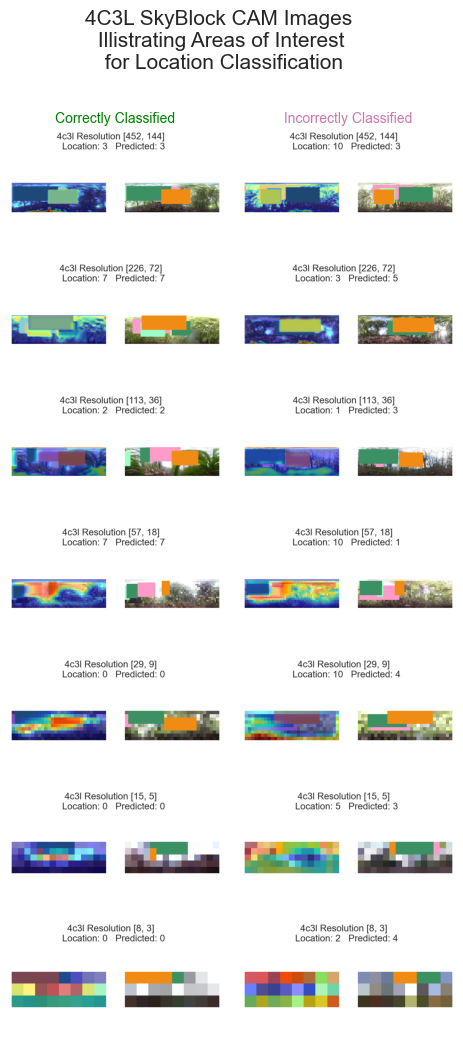

In [ ]:
# Exact spacing can be tweeked in CAMfns.py
multiCAMplot(m4_pix_both_cropped, "SkyBlock", '4C3L', w_space = -0.4, h_space =0)